In [3]:
# =========================================================================
# Author: M.D. Isuru Lakmal Peiris
# Automated Sandbox Breach Detection - Aho-Corasick Pre-Filtering Engine
# ===========================================================================

# ===========================================================================
# Phase 1: Aho-Corasick Engine Build (Custom Trie with Failure Links)
# ===========================================================================

from collections import deque
from typing import List, Dict, Optional, Tuple
import time
import pandas as pd

class TrieNode:
    """
    Represents a single character node within the Aho-Corasick automaton.
    """
    def __init__(self):
        # Dictionary mapping a character to its child TrieNode
        self.children: Dict[str, 'TrieNode'] = {}
        # Pointer to the next best fallback node if a mismatch occurs
        self.failure_link: Optional['TrieNode'] = None
        # List of malicious payloads that end at this specific node
        self.output_list: List[str] = []

class AhoCorasick:
    """
    Deterministic finite Automaton for high-speed multi-pattern matching.
    Time Complexity: O(N + M + Z) where N=text length, M=total pattern length, Z=matches.
    """
    def __init__(self):
        self.root = TrieNode()

    def add_pattern(self, pattern: str) -> None:
        """
        Inserts a malicious payload into the Trie structure.
        Time Complexity: O(L) where L is the length of the pattern.
        """
        if not pattern:
            return

        node = self.root
        for char in pattern:
            # If the path dosnt exist, create a new TrieNode
            if char not in node.children:
                node.children[char] = TrieNode()
            # Move to the child node
            node = node.children[char]
        # Mark the end of this malicious pattern
        node.output_list.append(pattern)

    def build_failure_links(self) -> None:
        """
        Constructs failure links using Breadth-First Search
        allows O(N) scanning by preventing backtracking.
        """
        queue = deque()

        # Initialize the first depth level (children of the root)
        # The failure link of roots children always points back to root
        for char, child in self.root.children.items():
            child.failure_link = self.root
            queue.append(child)

        #  BFS Traversal through the rest of the Trie
        while queue:
            current_node = queue.popleft()

            # Iterate through all children of the current node
            for char, child in current_node.children.items():
                queue.append(child)
                fallback = current_node.failure_link

                # Find the longest proper suffix
                # Trace back through failure links until we find a node that has
                # a child matching 'char', we hit the root
                while fallback and char not in fallback.children:
                    fallback = fallback.failure_link

                # Assign the failure link
                if fallback:
                    child.failure_link = fallback.children[char]
                else:
                    child.failure_link = self.root

                # Inherit outputs for overlapping patterns
                # If the failure link points to a node that marks the end of a pattern,
                # propagate that pattern to the current child to catch overlaps
                if child.failure_link:
                    child.output_list.extend(child.failure_link.output_list)

    def search(self, text: str) -> List[Tuple[int, str]]:
        """
        Scans continuous text in O(N + Z) time complexity.
        N = length of text, Z = number of matches found.
        """
        node = self.root
        results = []

        # Iterate through the text character by character
        for i, char in enumerate(text):
            # Handle mismatch by following failure links
            # While having a node and the current character doest match a child,
            # follow the failure link to find a fallback state.
            while node and char not in node.children:
                node = node.failure_link

            # Reset to root if no match found
            # If node is None, it means we fell back to nothing, so restart at root
            if not node:
                node = self.root
                continue

            #Transition to the matching child node
            node = node.children[char]

            # Record any malicious patterns ending at this position
            # If the current node has output patterns, calculate their start index
            # and append them to our results list
            if node.output_list:
                for pattern in node.output_list:
                    start_index = i - len(pattern) + 1
                    results.append((start_index, pattern))

        return results

In [4]:


# =============================================================================
# Phase 2: Data Ingestion (Local Priority with GitHub Fallback)
# ===========================================================================
import pandas as pd
import urllib.request
import urllib.error
import os

print("[*] Initiating Data Ingestion...")

# Source 1: Kaggle Dataset (Local CSV)
try:
    df = pd.read_csv("command-injection.csv")
    kaggle_payloads = df[df['Label'] == 1]['sentence'].dropna().astype(str).tolist()
    print(f"[+] Loaded {len(kaggle_payloads)} signatures from local Kaggle CSV.")
except FileNotFoundError:
    print("[!] ERROR: 'command-injection.csv' not found. Please ensure it is in the same directory.")
    kaggle_payloads = []

# Source 2: PayloadsAllTheThings (Local TXT with Dynamic GitHub Fallback)
github_payloads = []
try:
    # 1st Priority: Try reading the local downloaded file
    with open("command-execution-unix.txt", "r", encoding="utf-8") as f:
        github_payloads = [line.strip() for line in f.readlines() if line.strip()]
    print(f"[+] Loaded {len(github_payloads)} signatures from local TXT file.")

except FileNotFoundError:
    # 2nd Priority: Fallback to GitHub if local file is corrupted or blocked by security
    github_url = "https://raw.githubusercontent.com/swisskyrepo/PayloadsAllTheThings/master/Command%20Injection/Intruder/command-execution-unix.txt"
    try:
        print("[*] Local TXT not found. Fetching from GitHub as fallback...")
        response = urllib.request.urlopen(github_url)
        raw_text = response.read().decode('utf-8')
        github_payloads = [line.strip() for line in raw_text.split('\n') if line.strip()]
        print(f"[+] Loaded {len(github_payloads)} signatures from GitHub.")
    except urllib.error.URLError as e:
        print(f"[-] Could not reach GitHub ({e.reason}). Falling back to Kaggle data only.")

# Merge and Deduplicate
cmdi_signatures = list(set(kaggle_payloads + github_payloads))

print("="*50)
print(f"[SUCCESS] Total unique malicious signatures compiled: {len(cmdi_signatures)}")
print("="*50)


[*] Initiating Data Ingestion...
[+] Loaded 514 signatures from local Kaggle CSV.
[+] Loaded 83 signatures from local TXT file.
[SUCCESS] Total unique malicious signatures compiled: 492


In [5]:

# ==========================================================================
# Phase 3: Aho-Corasick Benchmark (O(N + M + Z))
# ==========================================================================


print("\n" + "="*50)
print("PHASE 3: Aho-Corasick Engine Benchmark")
print("="*50)

# Initialize the Engine
print("[*] Initializing Aho-Corasick Engine...")
waf_engine = AhoCorasick()

# Build the Automaton (Trie + Failure Links)
start_build = time.perf_counter()

for signature in cmdi_signatures:
    waf_engine.add_pattern(str(signature))

waf_engine.build_failure_links()  # Must be called after all patterns are inserted, before any search

end_build = time.perf_counter()
build_time = end_build - start_build

print(f"[+] Trie & Failure Links built in {build_time:.6f} seconds across {len(cmdi_signatures)} signatures.")

# Prepare a Complex Polyglot Payload (Simulating a Sandbox Escape Attempt)
simulated_prompt = 'Summarize this file: /*$(sleep 5)`sleep 5``*/-sleep(5)-"||sleep(5)||"/etc/passwd'
print(f"\n[*] Scanning incoming prompt ({len(simulated_prompt)} characters)...")

# Scan the Text using Aho-Corasick
start_scan = time.perf_counter()
threats_detected = waf_engine.search(simulated_prompt)  # Single-pass scan; O(N+Z) per call
end_scan = time.perf_counter()

scan_time = end_scan - start_scan

print(f"[+] Aho-Corasick scan completed in {scan_time:.6f} seconds.")
print(f"[!] Threats Detected: {len(threats_detected)}")
if threats_detected:
    print(f"    Sample match: {threats_detected[0]}")




PHASE 3: Aho-Corasick Engine Benchmark
[*] Initializing Aho-Corasick Engine...
[+] Trie & Failure Links built in 0.096560 seconds across 492 signatures.

[*] Scanning incoming prompt (80 characters)...
[+] Aho-Corasick scan completed in 0.000093 seconds.
[!] Threats Detected: 5
    Sample match: (25, 'sleep 5')


In [6]:


#===========================================================================
# Phase 4: Reference Baseline (Python Native 'in' Operator)
# ==========================================================================

print("\n" + "="*50)
print("PHASE 4: Reference Baseline Benchmark (Python Native 'in')")
print("="*50)

# Run the native approach to compare against the Aho-Corasick speed
print("[*] Running Native Baseline (checking each pattern individually)...")
start_naive = time.perf_counter()

# For every pattern check if it exists using CPythons highly optimized Two-Way search
for pattern in cmdi_signatures:
    if pattern in simulated_prompt:
        pass

end_naive = time.perf_counter()
naive_time = end_naive - start_naive

# Calculate the speedup factor
speedup = naive_time / scan_time if scan_time > 0 else float('inf')

print(f"[Native 'in'] Scan completed in {naive_time:.6f} seconds.")
print(f"[Aho-Corasick] Scan completed in {scan_time:.6f} seconds.")
print(f"[+] SPEEDUP: The Aho-Corasick engine is {speedup:.2f}x faster than Python's native C-optimized search!")

print("\n" + "="*50)
print("[NOTE] True O(N x M) complexity is demonstrated in the scaled Phase 5 benchmark.")
print("="*50)



PHASE 4: Reference Baseline Benchmark (Python Native 'in')
[*] Running Native Baseline (checking each pattern individually)...
[Native 'in'] Scan completed in 0.000363 seconds.
[Aho-Corasick] Scan completed in 0.000093 seconds.
[+] SPEEDUP: The Aho-Corasick engine is 3.89x faster than Python's native C-optimized search!

[NOTE] True O(N x M) complexity is demonstrated in the scaled Phase 5 benchmark.



PHASE 5: Scaled Benchmark & Visualization
[*] Running scaled benchmark...

Benchmark Results
-------------------------------------------------------------------------------------
Input Size     Naive (s)         Aho (s)           Speedup        
-------------------------------------------------------------------------------------
80             0.032212          0.000029          1102.66        x
400            0.179849          0.000124          1453.52        x
800            0.280156          0.000266          1054.00        x
2000           0.412851          0.000376          1098.89        x
4000           1.167171          0.000742          1573.97        x
8000           1.689429          0.001493          1131.57        x
20000          5.026704          0.003703          1357.35        x
40000          9.920506          0.008455          1173.37        x

[SUCCESS] Benchmark results exported to 'throughput_benchmark_results.csv'
 input_size_chars  naive_time_seconds  aho_cora

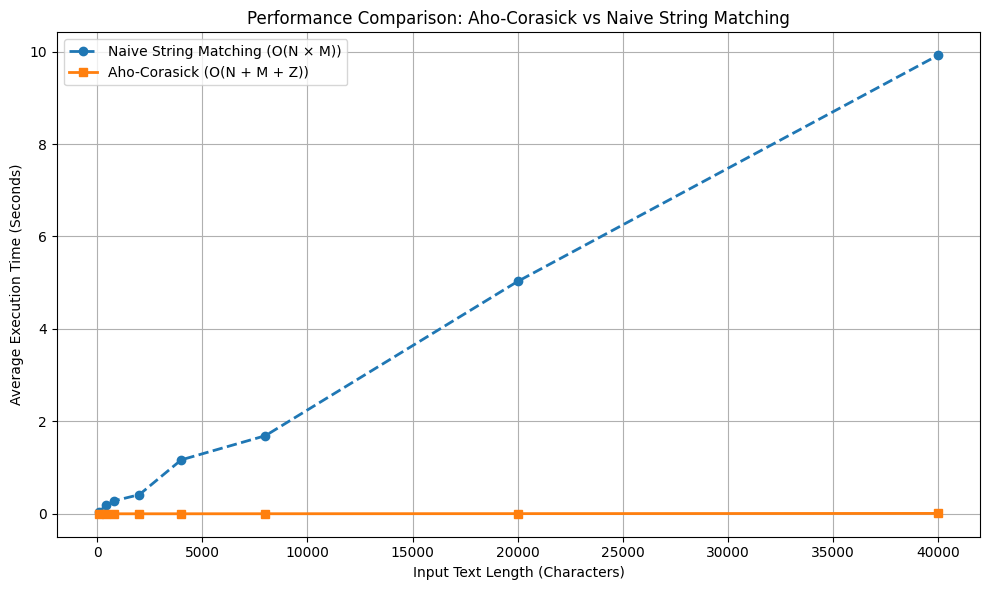


[SUCCESS] Benchmark graph exported as 'benchmark_results.png'


In [7]:

# ========================================================================
# Phase 5: Scaled Benchmark & Visualization
# ========================================================================

import time
import matplotlib.pyplot as plt

print("\n" + "=" * 60)
print("PHASE 5: Scaled Benchmark & Visualization")
print("=" * 60)

# -----------------
# Configuration
# -----------------

base_prompt = (
    'Summarize this file: '
    '/*$(sleep 5)`sleep 5``*/-sleep(5)-"||sleep(5)||"/etc/passwd'
)

# Different input sizes
multipliers = [1, 5, 10, 25, 50, 100, 250, 500]

# Number of benchmark repetitions
RUNS = 5

text_lengths = []
aho_times = []
naive_times = []

print("[*] Running scaled benchmark...")

# ----------------
# Benchmark Loop
# ----------------

for mult in multipliers:

    test_text = base_prompt * mult

    text_lengths.append(len(test_text))

    # ======================
    # Aho-Corasick Benchmark
    # ======================

    aho_total = 0.0

    for _ in range(RUNS):

        start = time.perf_counter()

        waf_engine.search(test_text)

        end = time.perf_counter()

        aho_total += (end - start)

    aho_average = aho_total / RUNS

    aho_times.append(aho_average)

    # =====================================
    # TRUE Naive String Matching Benchmark
    # =====================================

    naive_total = 0.0

    for _ in range(RUNS):

        start = time.perf_counter()

        for pattern in cmdi_signatures:

            pattern_length = len(pattern)
            text_length = len(test_text)

            if pattern_length == 0:
                continue

            # Slide pattern across text
            for i in range(text_length - pattern_length + 1):

                matched = True

                # Compare character-by-character
                for j in range(pattern_length):

                    if test_text[i + j] != pattern[j]:
                        matched = False
                        break

                if matched:
                    pass

        end = time.perf_counter()

        naive_total += (end - start)

    naive_average = naive_total / RUNS

    naive_times.append(naive_average)

# ---------------
# Print Results
# ---------------

print("\nBenchmark Results")
print("-" * 85)

print(
    f"{'Input Size':<15}"
    f"{'Naive (s)':<18}"
    f"{'Aho (s)':<18}"
    f"{'Speedup':<15}"
)

print("-" * 85)

for length, naive, aho in zip(text_lengths, naive_times, aho_times):

    speedup = naive / aho if aho > 0 else float("inf")

    print(
        f"{length:<15}"
        f"{naive:<18.6f}"
        f"{aho:<18.6f}"
        f"{speedup:<15.2f}x"
    )




# ---------------------------------
# Export Benchmark Results to CSV
# ---------------------------------
benchmark_results_df = pd.DataFrame({
    "input_size_chars": text_lengths,
    "naive_time_seconds": naive_times,
    "aho_corasick_time_seconds": aho_times,
    "speedup_factor": [n/a if a > 0 else float("inf") for n, a in zip(naive_times, aho_times)]
})

benchmark_results_df.to_csv("throughput_benchmark_results.csv", index=False)
print(f"\n[SUCCESS] Benchmark results exported to 'throughput_benchmark_results.csv'")
print(benchmark_results_df.to_string(index=False))

# ------------------
# Plot Graph
# ------------------

plt.figure(figsize=(10,6))

plt.plot(
    text_lengths,
    naive_times,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Naive String Matching (O(N × M))"
)

plt.plot(
    text_lengths,
    aho_times,
    marker="s",
    linewidth=2,
    label="Aho-Corasick (O(N + M + Z))"
)

plt.title("Performance Comparison: Aho-Corasick vs Naive String Matching")

plt.xlabel("Input Text Length (Characters)")

plt.ylabel("Average Execution Time (Seconds)")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig("benchmark_results.png", dpi=300, bbox_inches="tight")

plt.show()

print("\n[SUCCESS] Benchmark graph exported as 'benchmark_results.png'")



In [8]:


# ===========================================================================
# Phase 6: Security Evaluation (False Negative Rate / False Positive Rate)
# ============================================================================

print("\n" + "="*60)
print("PHASE 6: Security Evaluation - FNR / FPR Analysis")
print("="*60)

# ------------------------------------------------------------------
# Load a Benign Log Corpus (Local Priority with Fallback)
# ------------------------------------------------------------------
# need a set of KNOWN-SAFE log lines to test for false positives.
# I found Loghub's OpenSSH dataset is a standard, citable benchmark of benign
# system logs, widely used in log-analysis research.

benign_logs = []

try:
    # 1st Priority: Local file if already downloaded
    with open("openssh_benign_logs.txt", "r", encoding="utf-8") as f:
        benign_logs = [line.strip() for line in f.readlines() if line.strip()]
    print(f"[+] Loaded {len(benign_logs)} benign log lines from local file.")

except FileNotFoundError:
    # 2nd Priority: Fallback to Loghub's raw GitHub sample
    loghub_url = "https://raw.githubusercontent.com/logpai/loghub/master/OpenSSH/OpenSSH_2k.log"
    try:
        print("[*] Local benign log file not found. Fetching from Loghub (GitHub)...")
        response = urllib.request.urlopen(loghub_url)
        raw_text = response.read().decode('utf-8', errors='ignore')
        benign_logs = [line.strip() for line in raw_text.split('\n') if line.strip()]
        print(f"[+] Loaded {len(benign_logs)} benign log lines from Loghub GitHub.")
    except urllib.error.URLError as e:
        print(f"[-] Could not reach Loghub ({e.reason}). Using a small fallback benign sample.")
        # 3rd Priority: Minimal built-in fallback so the script never crashes
        benign_logs = [
            "Accepted password for user1 from 192.168.1.5 port 22 ssh2",
            "Connection closed by 192.168.1.10 port 51422",
            "session opened for user admin by (uid=0)",
            "Failed password for invalid user test from 10.0.0.5 port 44212 ssh2",
            "Received disconnect from 192.168.1.20: 11: disconnected by user",
        ]

print(f"[SUCCESS] Benign log corpus ready: {len(benign_logs)} lines.")


# ------------------------------------------------------------------
# Run Aho-Corasick Against the MALICIOUS Set (Recall / FNR)
# ------------------------------------------------------------------
# For every known-malicious payload, check whether the engine detects it
# when embedded in a realistic log-style sentence.

print("\n[*] Evaluating detection rate on malicious payload set...")

true_positives = 0
false_negatives = 0
missed_payloads = []

for payload in cmdi_signatures:
    # Wrap the payload in a small log-like context, similar to real usage
    test_line = f"user_input: {payload}"
    matches = waf_engine.search(test_line)

    if matches:
        true_positives += 1
    else:
        false_negatives += 1
        missed_payloads.append(payload)

total_malicious = len(cmdi_signatures)
recall = true_positives / total_malicious if total_malicious > 0 else 0
false_negative_rate = false_negatives / total_malicious if total_malicious > 0 else 0

print(f"[+] Total malicious payloads tested: {total_malicious}")
print(f"[+] True Positives (correctly flagged): {true_positives}")
print(f"[+] False Negatives (missed): {false_negatives}")
print(f"[+] Recall (Detection Rate): {recall:.4f} ({recall*100:.2f}%)")
print(f"[+] False Negative Rate: {false_negative_rate:.4f} ({false_negative_rate*100:.2f}%)")

# ------------------------------------------------------------------
#Run Aho-Corasick Against the BENIGN Set (Specificity / FPR)
# ------------------------------------------------------------------
# For every known-safe log line, check whether the engine incorrectly
# flags it as malicious.

print("\n[*] Evaluating false positive rate on benign log set...")

true_negatives = 0
false_positives = 0
false_positive_lines = []

for line in benign_logs:
    matches = waf_engine.search(line)

    if matches:
        false_positives += 1
        false_positive_lines.append((line, matches))
    else:
        true_negatives += 1

total_benign = len(benign_logs)
specificity = true_negatives / total_benign if total_benign > 0 else 0
false_positive_rate = false_positives / total_benign if total_benign > 0 else 0

print(f"[+] Total benign log lines tested: {total_benign}")
print(f"[+] True Negatives (correctly passed): {true_negatives}")
print(f"[+] False Positives (incorrectly flagged): {false_positives}")
print(f"[+] Specificity: {specificity:.4f} ({specificity*100:.2f}%)")
print(f"[+] False Positive Rate: {false_positive_rate:.4f} ({false_positive_rate*100:.2f}%)")

# -----------------------------
# Summary Table
# ----------------------------

print("\n" + "="*60)
print("SECURITY EVALUATION SUMMARY")
print("="*60)
print(f"{'Metric':<30}{'Value':<15}")
print("-"*45)
print(f"{'Recall (Detection Rate)':<30}{recall*100:.2f}%")
print(f"{'False Negative Rate':<30}{false_negative_rate*100:.2f}%")
print(f"{'Specificity':<30}{specificity*100:.2f}%")
print(f"{'False Positive Rate':<30}{false_positive_rate*100:.2f}%")
print("="*60)

if missed_payloads:
    print(f"\n[NOTE] Sample of missed payloads (first 3): {missed_payloads[:3]}")
if false_positive_lines:
    print(f"[NOTE] Sample false positive (first 1): {false_positive_lines[:1]}")




PHASE 6: Security Evaluation - FNR / FPR Analysis
[+] Loaded 2000 benign log lines from local file.
[SUCCESS] Benign log corpus ready: 2000 lines.

[*] Evaluating detection rate on malicious payload set...
[+] Total malicious payloads tested: 492
[+] True Positives (correctly flagged): 492
[+] False Negatives (missed): 0
[+] Recall (Detection Rate): 1.0000 (100.00%)
[+] False Negative Rate: 0.0000 (0.00%)

[*] Evaluating false positive rate on benign log set...
[+] Total benign log lines tested: 2000
[+] True Negatives (correctly passed): 1354
[+] False Positives (incorrectly flagged): 646
[+] Specificity: 0.6770 (67.70%)
[+] False Positive Rate: 0.3230 (32.30%)

SECURITY EVALUATION SUMMARY
Metric                        Value          
---------------------------------------------
Recall (Detection Rate)       100.00%
False Negative Rate           0.00%
Specificity                   67.70%
False Positive Rate           32.30%
[NOTE] Sample false positive (first 1): [('Dec 10 06:55:46 

[SAVED] Baseline results captured for comparison.
{'condition': 'Unfiltered (Baseline)', 'total_signatures': 492, 'recall': 1.0, 'false_negative_rate': 0.0, 'specificity': 0.677, 'false_positive_rate': 0.323}
[*] Signature filtering: 492 -> 475 (removed 17 patterns shorter than 4 chars)
[*] Removed signatures (17): ['dir', '\'"', '|id', 'pwd', "'", '|| ', '& ', '`', '%0a', '\\n', '&& ', '| ', "\r\n'", ';id', '\\r', '; ', 'ls']
[+] Filtered engine rebuilt with 475 signatures.

[*] Evaluating FILTERED engine on malicious payload set...
[+] Recall: 100.00%  |  FNR: 0.00%

[*] Evaluating FILTERED engine on benign log set...
[+] Specificity: 100.00%  |  FPR: 0.00%

BEFORE / AFTER COMPARISON: Signature Length Filtering
              condition  total_signatures  recall  false_negative_rate  specificity  false_positive_rate
  Unfiltered (Baseline)               492   100.0                  0.0         67.7                 32.3
Filtered (min length=4)               475   100.0                  

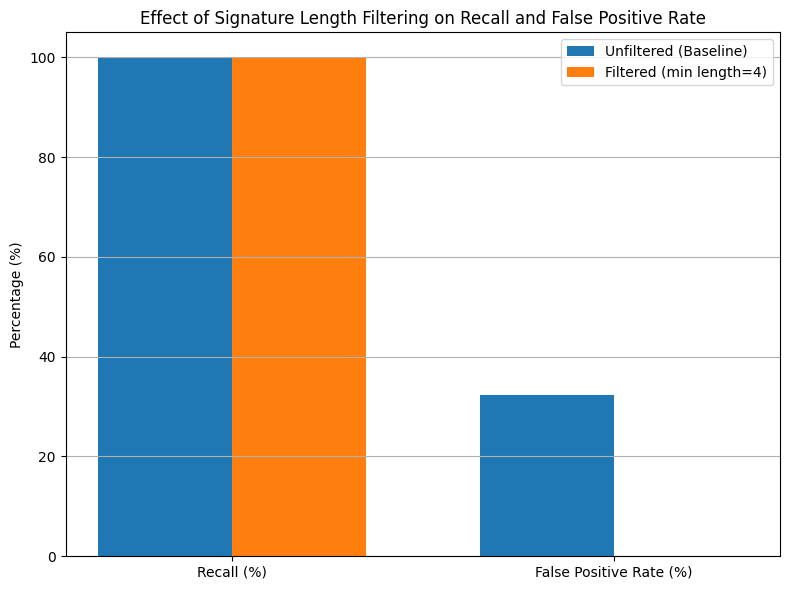

[SUCCESS] Comparison chart exported as 'fnr_fpr_comparison_chart.png'


In [9]:

# ======================================================================
# Phase 7: Signature Refinement Experiment (Before/After Comparison)
# ======================================================================

# -------------------------------------------------
# Save Baseline (Unfiltered) Results for Comparison
# -------------------------------------------------
baseline_results = {
    "condition": "Unfiltered (Baseline)",
    "total_signatures": len(cmdi_signatures),
    "recall": recall,
    "false_negative_rate": false_negative_rate,
    "specificity": specificity,
    "false_positive_rate": false_positive_rate
}
print("[SAVED] Baseline results captured for comparison.")
print(baseline_results)




# ------------------------------------------------------------------
# Signature Quality Filter: Remove overly short/generic patterns
# ------------------------------------------------------------------
# Signatures shorter than MIN_PATTERN_LENGTH are too generic and
# trigger excessive false positives on benign text (e.g. "; ", "-", "||").
# This directly addresses the "Semantic Stripping" limitation identified
# in Part I Section 3.6.

MIN_PATTERN_LENGTH = 4

original_count = len(cmdi_signatures)
filtered_signatures = [sig for sig in cmdi_signatures if len(sig.strip()) >= MIN_PATTERN_LENGTH]
filtered_count = len(filtered_signatures)

print(f"[*] Signature filtering: {original_count} -> {filtered_count} "
      f"(removed {original_count - filtered_count} patterns shorter than {MIN_PATTERN_LENGTH} chars)")

#
removed_signatures = [sig for sig in cmdi_signatures if len(sig.strip()) < MIN_PATTERN_LENGTH]
print(f"[*] Removed signatures ({len(removed_signatures)}): {removed_signatures}")

# -------------------------------------------------------=
# Rebuild a FRESH engine using only the filtered signatures
# --------------------------------------------------------
filtered_engine = AhoCorasick()

for signature in filtered_signatures:
    filtered_engine.add_pattern(str(signature))

filtered_engine.build_failure_links()

print(f"[+] Filtered engine rebuilt with {filtered_count} signatures.")




# ------------------------------------------------------------------
# Re-evaluate: Filtered Engine - Malicious Set (Recall / FNR)
# ------------------------------------------------------------------
print("\n[*] Evaluating FILTERED engine on malicious payload set...")

tp_f = 0
fn_f = 0
missed_f = []

for payload in filtered_signatures:
    test_line = f"user_input: {payload}"
    matches = filtered_engine.search(test_line)
    if matches:
        tp_f += 1
    else:
        fn_f += 1
        missed_f.append(payload)

total_malicious_f = len(filtered_signatures)
recall_f = tp_f / total_malicious_f if total_malicious_f > 0 else 0
fnr_f = fn_f / total_malicious_f if total_malicious_f > 0 else 0

print(f"[+] Recall: {recall_f*100:.2f}%  |  FNR: {fnr_f*100:.2f}%")

# -------------------------------------------------------------
# Re-evaluate: Filtered Engine - Benign Set (Specificity / FPR)
# -------------------------------------------------------------
print("\n[*] Evaluating FILTERED engine on benign log set...")

tn_f = 0
fp_f = 0
fp_lines_f = []

for line in benign_logs:
    matches = filtered_engine.search(line)
    if matches:
        fp_f += 1
        fp_lines_f.append((line, matches))
    else:
        tn_f += 1

total_benign_f = len(benign_logs)
specificity_f = tn_f / total_benign_f if total_benign_f > 0 else 0
fpr_f = fp_f / total_benign_f if total_benign_f > 0 else 0

print(f"[+] Specificity: {specificity_f*100:.2f}%  |  FPR: {fpr_f*100:.2f}%")

filtered_results = {
    "condition": f"Filtered (min length={MIN_PATTERN_LENGTH})",
    "total_signatures": total_malicious_f,
    "recall": recall_f,
    "false_negative_rate": fnr_f,
    "specificity": specificity_f,
    "false_positive_rate": fpr_f
}



# -----------------------------------
# Before / After Comparison Table
# -----------------------------------
import pandas as pd

comparison_df = pd.DataFrame([baseline_results, filtered_results])
comparison_df["recall"] = (comparison_df["recall"] * 100).round(2)
comparison_df["false_negative_rate"] = (comparison_df["false_negative_rate"] * 100).round(2)
comparison_df["specificity"] = (comparison_df["specificity"] * 100).round(2)
comparison_df["false_positive_rate"] = (comparison_df["false_positive_rate"] * 100).round(2)

print("\n" + "="*60)
print("BEFORE / AFTER COMPARISON: Signature Length Filtering")
print("="*60)
print(comparison_df.to_string(index=False))

comparison_df.to_csv("fnr_fpr_comparison.csv", index=False)
print("\n[SUCCESS] Comparison exported to 'fnr_fpr_comparison.csv'")

# -------------------------------
# Bar Chart: Before vs After
# -------------------------------
import matplotlib.pyplot as plt
import numpy as np

metrics = ["recall", "false_positive_rate"]
labels = ["Recall (%)", "False Positive Rate (%)"]
x = np.arange(len(labels))
width = 0.35

baseline_vals = [baseline_results["recall"]*100, baseline_results["false_positive_rate"]*100]
filtered_vals = [filtered_results["recall"]*100, filtered_results["false_positive_rate"]*100]

fig, ax = plt.subplots(figsize=(8,6))
ax.bar(x - width/2, baseline_vals, width, label="Unfiltered (Baseline)")
ax.bar(x + width/2, filtered_vals, width, label=f"Filtered (min length={MIN_PATTERN_LENGTH})")

ax.set_ylabel("Percentage (%)")
ax.set_title("Effect of Signature Length Filtering on Recall and False Positive Rate")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(True, axis="y")

plt.tight_layout()
plt.savefig("fnr_fpr_comparison_chart.png", dpi=300, bbox_inches="tight")
plt.show()

print("[SUCCESS] Comparison chart exported as 'fnr_fpr_comparison_chart.png'")





In [10]:

# ========================================================================
# Phase 8: Space Complexity Analysis (Trie Node Count & Memory Footprint)
# ========================================================================

import sys

print("\n" + "="*60)
print("PHASE 8: Space Complexity Analysis")
print("="*60)

def analyze_trie_space(engine: AhoCorasick, label: str) -> dict:
    """
    Traverses the Trie via BFS to count nodes, edges, and estimate
    memory footprint. This empirically validates the theoretical
    space complexity of O(M), where M is the total length of all
    inserted patterns.
    """
    visited = set()
    queue = deque([engine.root])
    node_count = 0
    edge_count = 0
    total_output_entries = 0
    max_depth = 0

    # BFS traversal to visit every node exactly once
    depths = {id(engine.root): 0}

    while queue:
        current = queue.popleft()
        if id(current) in visited:
            continue
        visited.add(id(current))
        node_count += 1

        current_depth = depths[id(current)]
        max_depth = max(max_depth, current_depth)

        total_output_entries += len(current.output_list)

        for char, child in current.children.items():
            edge_count += 1
            if id(child) not in depths:
                depths[id(child)] = current_depth + 1
            queue.append(child)

    # ------------------------------------------------------------
    # Memory Estimation
    # ------------------------------------------------------------
    # sys.getsizeof only measures the shallow size of an object,
    # so i approximate per-node cost by sampling a real node's
    # base size plus its children dict and output list overhead.
    sample_node = TrieNode()
    base_node_size = sys.getsizeof(sample_node)
    dict_overhead = sys.getsizeof({})
    list_overhead = sys.getsizeof([])

    estimated_bytes = node_count * (base_node_size + dict_overhead + list_overhead)
    estimated_kb = estimated_bytes / 1024

    results = {
        "condition": label,
        "node_count": node_count,
        "edge_count": edge_count,
        "max_trie_depth": max_depth,
        "total_output_entries": total_output_entries,
        "estimated_memory_bytes": estimated_bytes,
        "estimated_memory_kb": round(estimated_kb, 2)
    }

    print(f"\n--- {label} ---")
    print(f"[+] Total Trie Nodes:        {node_count}")
    print(f"[+] Total Edges (transitions): {edge_count}")
    print(f"[+] Maximum Trie Depth:      {max_depth}")
    print(f"[+] Total Output Entries:    {total_output_entries} "
          f"(includes inherited outputs from failure links)")
    print(f"[+] Estimated Memory Usage:  {estimated_bytes:,} bytes (~{estimated_kb:.2f} KB)")

    return results

# ------------------------------------------------------------
# Run analysis on BOTH engines for a before/after comparison
# ------------------------------------------------------------
space_unfiltered = analyze_trie_space(waf_engine, "Unfiltered Engine")
space_filtered = analyze_trie_space(filtered_engine, f"Filtered Engine (min length={MIN_PATTERN_LENGTH})")

# ----------------------------
# Comparison Table
# --------------------------
space_comparison_df = pd.DataFrame([space_unfiltered, space_filtered])

print("\n" + "="*60)
print("SPACE COMPLEXITY COMPARISON")
print("="*60)
print(space_comparison_df.to_string(index=False))

space_comparison_df.to_csv("space_complexity_comparison.csv", index=False)
print("\n[SUCCESS] Space complexity results exported to 'space_complexity_comparison.csv'")

# ------------------------------------------------------------------
# Empirical Validation: Node Count vs. Total Pattern Length (M)
# ------------------------------------------------------------------
# This directly tests the theoretical claim that space is O(M),
# by comparing node_count against the sum of all pattern lengths.

total_pattern_length_unfiltered = sum(len(s) for s in cmdi_signatures)
total_pattern_length_filtered = sum(len(s) for s in filtered_signatures)

print("\n" + "="*60)
print("EMPIRICAL VALIDATION: Node Count vs Total Pattern Length (M)")
print("="*60)
print(f"{'Condition':<35}{'Total Chars (M)':<18}{'Trie Nodes':<15}{'Nodes/M Ratio':<15}")
print("-"*83)
print(f"{'Unfiltered':<35}{total_pattern_length_unfiltered:<18}"
      f"{space_unfiltered['node_count']:<15}"
      f"{space_unfiltered['node_count']/total_pattern_length_unfiltered:<15.4f}")
print(f"{'Filtered':<35}{total_pattern_length_filtered:<18}"
      f"{space_filtered['node_count']:<15}"
      f"{space_filtered['node_count']/total_pattern_length_filtered:<15.4f}")
print("\n[NOTE] A Nodes/M ratio below 1.0 confirms sub-linear growth due to shared")
print("       prefixes in the Trie (e.g. overlapping command patterns), which is")
print("       expected behaviour and demonstrates the space efficiency of the")
print("       Trie structure relative to storing patterns as separate strings.")






PHASE 8: Space Complexity Analysis

--- Unfiltered Engine ---
[+] Total Trie Nodes:        14889
[+] Total Edges (transitions): 14888
[+] Maximum Trie Depth:      1524
[+] Total Output Entries:    1204 (includes inherited outputs from failure links)
[+] Estimated Memory Usage:  2,501,352 bytes (~2442.73 KB)

--- Filtered Engine (min length=4) ---
[+] Total Trie Nodes:        14883
[+] Total Edges (transitions): 14882
[+] Maximum Trie Depth:      1524
[+] Total Output Entries:    839 (includes inherited outputs from failure links)
[+] Estimated Memory Usage:  2,500,344 bytes (~2441.74 KB)

SPACE COMPLEXITY COMPARISON
                     condition  node_count  edge_count  max_trie_depth  total_output_entries  estimated_memory_bytes  estimated_memory_kb
             Unfiltered Engine       14889       14888            1524                  1204                 2501352              2442.73
Filtered Engine (min length=4)       14883       14882            1524                   839       

In [11]:


# =============================================================================
# Unit Testing & Validation
# =============================================================================
print("[*] Running Unit Tests...")

test_engine = AhoCorasick()
test_engine.add_pattern("cat /etc/passwd")
test_engine.add_pattern("rm -rf")
test_engine.build_failure_links()

test_string_1 = "User input: cat /etc/passwd && echo done"
test_string_2 = "Safe string with no threats"

# Test 1: Expected match
results_1 = test_engine.search(test_string_1)
assert len(results_1) == 1, "Test 1 Failed"
assert results_1[0][1] == "cat /etc/passwd", "Test 1 Match Failed"

# Test 2: No match
results_2 = test_engine.search(test_string_2)
assert len(results_2) == 0, "Test 2 Failed"

print("[SUCCESS] All unit tests passed. Engine accurately identifies payloads without false positives.")

[*] Running Unit Tests...
[SUCCESS] All unit tests passed. Engine accurately identifies payloads without false positives.
